# How the correctness model differs between participants

The headline model predicts, from eye movements over the answer options, whether a participant picks the correct answer. Here the same logistic regression, with the same features, is fitted separately for each Study 1 participant (360 people, 54 trials each), on that person's trials alone. "LOO" means leave one *trial* out, never a person: each of a person's trials is predicted by a model trained on their other trials, which gives every participant an accuracy of their own, and one more fit on all of their trials gives their coefficients. From these per-person models the notebook looks at how accuracy is spread across people, which features the models rely on and whether they point the same way for everyone, what sets apart the people the model predicts well, and which kinds of mistakes it makes. Three caveats run through all of it. Each model rests on about 54 trials, so part of the spread between people is estimation noise rather than a real difference, and none of the numbers here is a significance test. Each fit standardises the features within the person, so a coefficient is per standard deviation of that person's own values. And most answers are correct (about 84%), so raw accuracy has to be read against that share, and balanced accuracy is unreliable for people with few wrong answers.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import time

import matplotlib.pyplot as plt

import src.config.columns as Con
import src.modeling.feature_sets as FG
from src.features.build import load_model_ready
from src.modeling.models.logreg_model import TrialLevelLogRegModel
from src.analyses.correctness_prediction.participant_level import (
    evaluate_logreg_on_answer_correctness_full_loo,
)
from src.analyses.correctness_prediction.person_variance import (
    accuracy_characterization as AC,
    coef_consistency as CC,
    loo_runs,
    mistake_types as MT,
    person_accuracy as PA,
    univariate_consistency as UC,
)

trial_df = load_model_ready()   # Study 1, one row per participant x trial

FEATURE_COLS = loo_runs.DEFAULT_FEATURE_COLS        # the 12 features of the per-person models
FEATURE_SET_TAG = loo_runs.DEFAULT_FEATURE_SET_TAG  # only names the feature set in figure titles here
ALL_FEATURE_COLS = [c for c in FG.ALL_FEATURES if c in trial_df.columns]

print(f"{len(trial_df)} trials from {trial_df[Con.PARTICIPANT_ID].nunique()} participants")
print(f"{len(FEATURE_COLS)} model features; {len(ALL_FEATURE_COLS)} of {len(FG.ALL_FEATURES)} features in the table")

19436 trials from 360 participants
12 model features; 98 of 98 features in the table


## 1. One model per participant
*`loo_runs.py`, `participant_level.py`*

For every participant, each trial is held out in turn and predicted by a model trained on their remaining trials; the held-out predictions are pooled into one result per person. One more fit, on all of their trials, gives the coefficients used in section 3. The model and features are the headline model's, plus whether the last area looked at before confirming was the correct answer or the question: 12 features in all. A participant whose answers are all correct (or all wrong) gets no model, and a trial whose removal would leave only one outcome to train on is not scored.

The run is computed from scratch here and kept in memory only, so this cell takes several minutes.

In [2]:
t0 = time.perf_counter()
results_by_pid = evaluate_logreg_on_answer_correctness_full_loo(
    trial_df=trial_df,
    feature_cols=FEATURE_COLS,
    model_builder=lambda: TrialLevelLogRegModel(),
    verbose=False,
)
print(f"{len(results_by_pid)} participants got a model, "
      f"{sum(r.n_test for r in results_by_pid.values())} trials scored "
      f"({time.perf_counter() - t0:.0f} s)")
print("Features:", *FEATURE_COLS, sep="\n  ")

# Who got no model, and why: their trial count and how many they answered correctly.
no_model = trial_df[~trial_df[Con.PARTICIPANT_ID].isin(list(results_by_pid))]
no_model.groupby(Con.PARTICIPANT_ID)[Con.IS_CORRECT_COLUMN].agg(n_trials="size", n_correct="sum")

356 participants got a model, 19215 trials scored (303 s)
Features:
  area_dwell_proportion__correct
  area_dwell_proportion__question
  skip_rate__correct
  has_xyx
  ANSWER_PRESS_NUMBER
  num_label_visits__correct
  num_label_visits__contrast
  mean_fixations_count__question
  mean_fixations_count__wrong_mean
  mean_max_fix_pupil_size_z__correct
  last_before_confirm_correct
  last_before_confirm_question


,n_trials,n_correct
participant_id,,
l10_494,54,54
l11_40,54,54
l13_42,54,54
l49_510,54,54


## 2. How well each person is predicted
*`person_accuracy.py`*

One row per participant: the trials scored, how many of them were answered correctly and wrongly, and the share the person's own model got right, raw and balanced. Balanced accuracy averages how often the model is right on correct answers and how often on wrong ones, so calling every answer correct scores 0.5. It is missing for someone with a single wrong answer, because that trial is never scored. The table is sorted best balanced accuracy first.

In the histograms the dotted line at 0.5 is chance for balanced accuracy only. For raw accuracy the bar to beat is the share of correct answers, printed above the table: a model that calls every answer correct already scores that.

Mean per-person accuracy:           0.8321
Mean per-person balanced accuracy:  0.7396
Share of scored trials answered correctly: 0.8391
Participants without a balanced accuracy: 5


,participant_id,n_trials,n_correct_trials,n_wrong_trials,accuracy,balanced_accuracy
0,l9_38,54,49,5,1.000,1.000
1,l35_264,54,50,4,1.000,1.000
2,l9_201,54,48,6,1.000,1.000
3,l53_478,54,46,8,0.981,0.989
4,l55_435,54,46,8,0.981,0.989
...,...,...,...,...,...,...
351,l52_428,53,53,0,0.962,NaN
352,l6_83,53,53,0,1.000,NaN
353,l59_293,53,53,0,0.792,NaN
354,l59_504,53,53,0,0.962,NaN


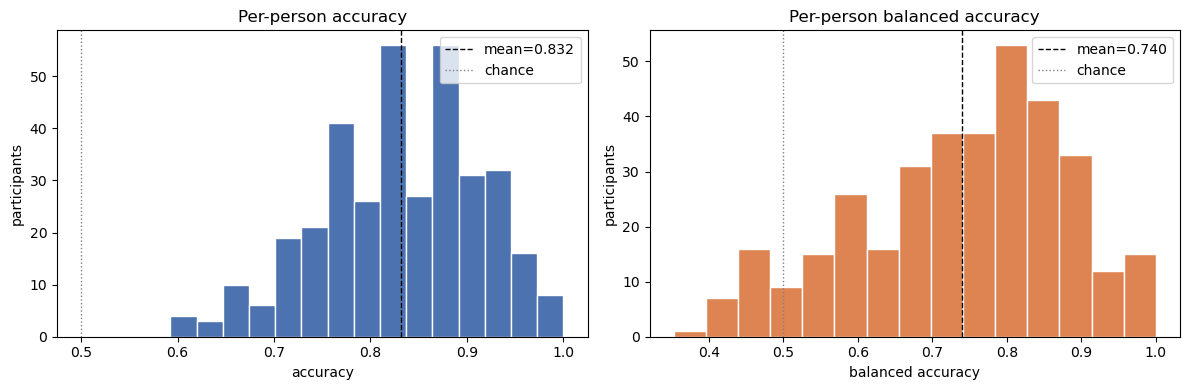

In [3]:
summary_df = PA.per_person_summary(results_by_pid, verbose=True)
print("Share of scored trials answered correctly:",
      round(summary_df["n_correct_trials"].sum() / summary_df["n_trials"].sum(), 4))
print("Participants without a balanced accuracy:", summary_df["balanced_accuracy"].isna().sum())
display(summary_df.round(3))
fig, _ = PA.plot_per_person_accuracy_hist(summary_df, save=False)

## 3. What the per-person models rely on
*`coef_consistency.py`*

Everyone's model has the same 12 features, so a feature's coefficient can be compared across people. A positive coefficient means more of that feature goes with a higher predicted chance of a correct answer. The next three figures (presence, average rank, average coefficient) are drawn by shared helpers in `plots/`, which use their own colours.

- **Presence:** how many participants have the feature among their 3 largest coefficients by size. The bar colour is the sign most of them share, and `!n` marks n of them with the other sign.
- **Average rank:** rank 1 is a person's largest coefficient by size, so a low average means the feature is consistently among the most important.

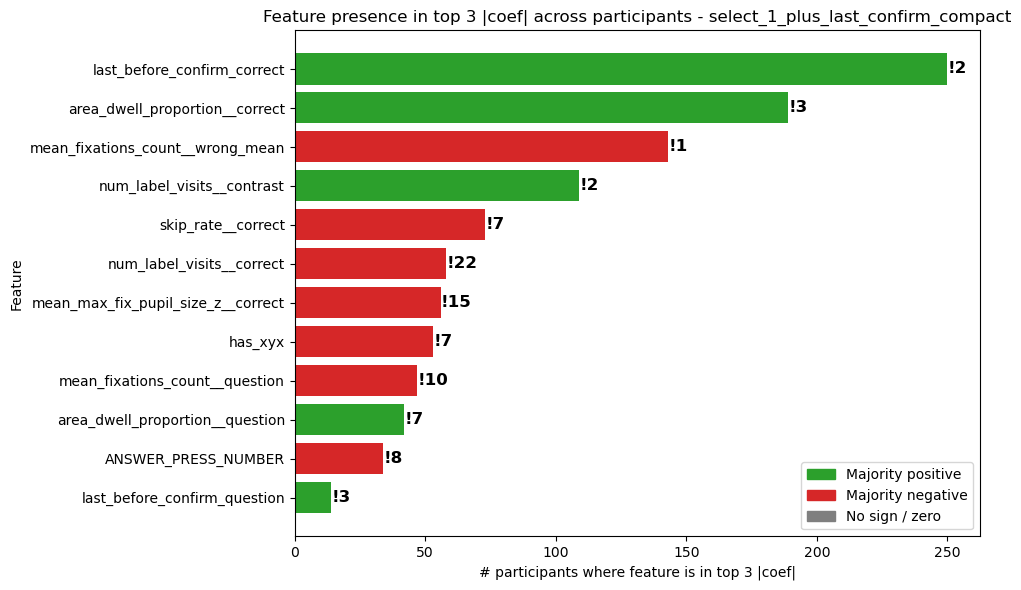

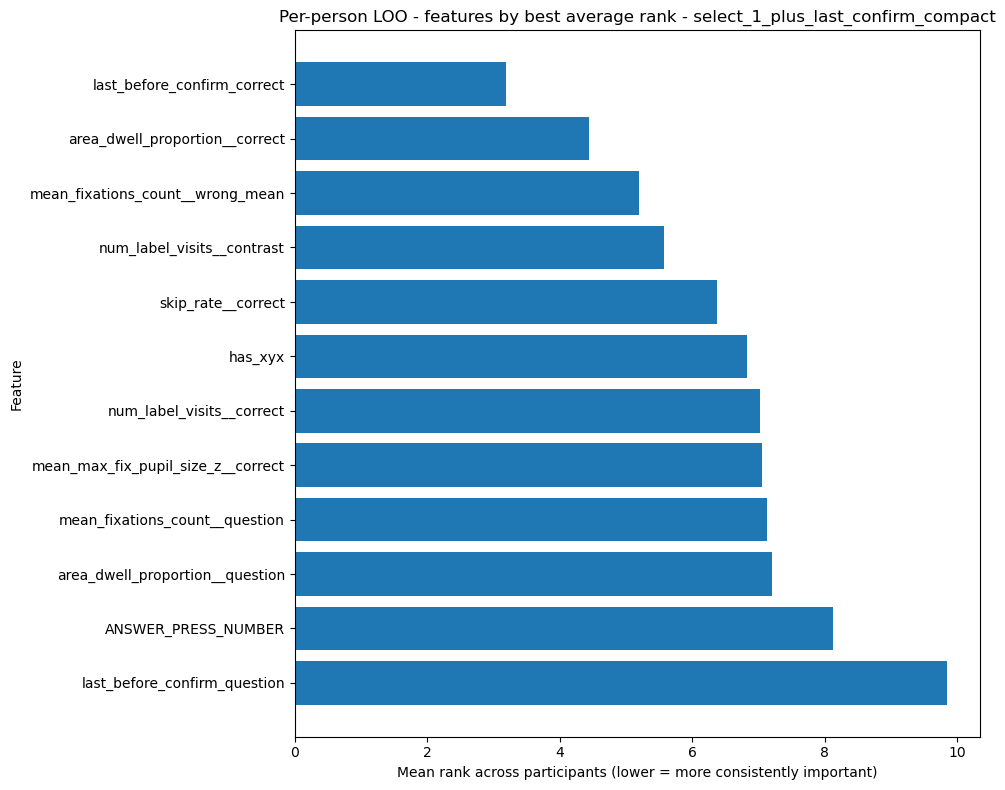

In [4]:
fig, presence_df, _ = CC.plot_feature_presence_across_participants(
    results_by_pid, feature_set_tag=FEATURE_SET_TAG, top_k_within_participant=3, save=False,
)
fig, avg_rank_df, _ = CC.plot_feature_avg_rank_across_participants(
    results_by_pid, feature_set_tag=FEATURE_SET_TAG, save=False,
)

### The average coefficient

Each feature's coefficient averaged over all participants. The whiskers are the mean plus and minus one standard deviation across people: how much the effect changes from person to person, not a confidence interval.

,feature,coef,std,n_participants,abs_coef,ci_low,ci_high
0,last_before_confirm_correct,1.048,0.614,356,1.048,0.434,1.662
1,area_dwell_proportion__correct,0.743,0.577,356,0.743,0.166,1.320
2,mean_fixations_count__wrong_mean,-0.625,0.492,356,0.625,-1.118,-0.133
3,num_label_visits__contrast,0.552,0.467,356,0.552,0.085,1.018
4,skip_rate__correct,-0.299,0.531,356,0.299,-0.830,0.232
5,area_dwell_proportion__question,0.199,0.489,356,0.199,-0.290,0.687
6,has_xyx,-0.194,0.528,356,0.194,-0.722,0.334
7,mean_max_fix_pupil_size_z__correct,-0.165,0.556,356,0.165,-0.721,0.391
8,mean_fixations_count__question,-0.113,0.512,356,0.113,-0.624,0.399
9,last_before_confirm_question,0.098,0.301,356,0.098,-0.203,0.399


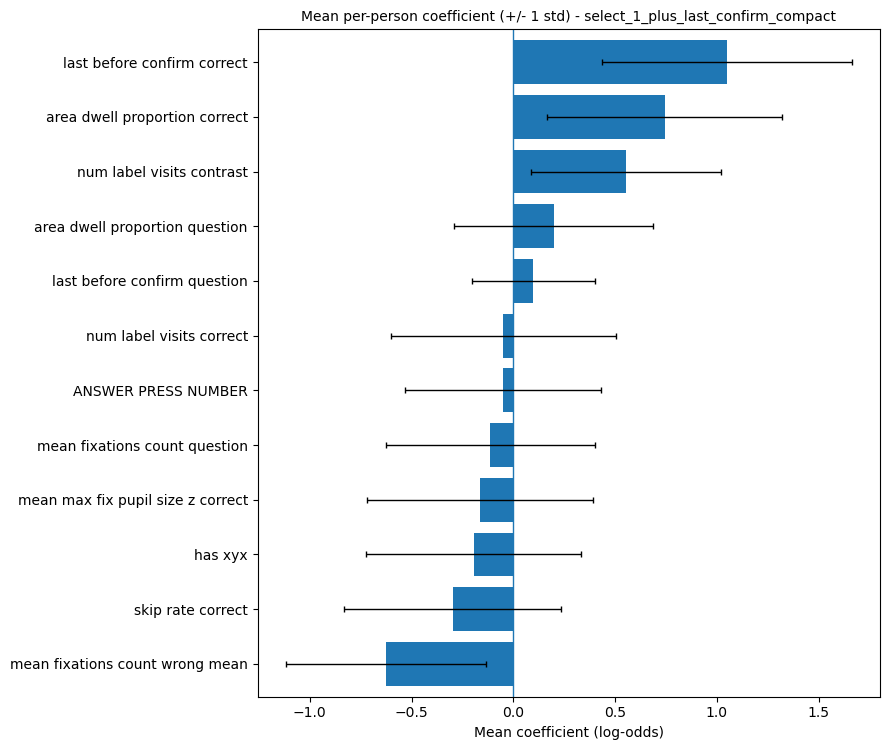

In [5]:
mean_coef_df = CC.mean_coef_across_participants(results_by_pid)
display(mean_coef_df.round(3))
fig, _, _ = CC.plot_mean_coef_across_participants(
    mean_coef_df, feature_set_tag=FEATURE_SET_TAG, save=False,
)

### Which features mean the same thing for everyone?

Features are sorted from most to least consistent. **Left:** the share of participants whose coefficient is negative (orange), zero (grey) or positive (blue), with the share of the more common sign beside each bar. A nearly solid bar means people agree on the direction; two colours mean the effect changes sign between people; a wide grey band means the feature never varied within many people's trials, so their model could not use it. **Right:** each person's coefficient divided by the feature's average size, so features of different size can be compared. Tight around +1 or -1 means a similar effect for everyone; spread across 0 means it varies. `dispersion_index` in the table is that spread as one number: 0 means identical for everyone, above 1 means the spread is larger than the typical size.

Because each fit rests on about 54 trials, read this as an upper bound on how inconsistent a feature is.

,feature,n_participants,mean,share_negative,share_zero,share_positive,dominant_share,dispersion_index
0,last_before_confirm_correct,356,1.048,0.065,0.000,0.935,0.935,0.562
1,area_dwell_proportion__correct,356,0.743,0.101,0.000,0.899,0.899,0.709
2,mean_fixations_count__wrong_mean,356,-0.625,0.890,0.000,0.110,0.890,0.724
3,num_label_visits__contrast,356,0.552,0.132,0.000,0.868,0.868,0.755
4,skip_rate__correct,356,-0.299,0.697,0.000,0.303,0.697,1.055
5,area_dwell_proportion__question,356,0.199,0.329,0.000,0.671,0.671,1.156
6,has_xyx,356,-0.194,0.652,0.000,0.348,0.652,1.165
7,mean_max_fix_pupil_size_z__correct,356,-0.165,0.626,0.000,0.374,0.626,1.243
8,mean_fixations_count__question,356,-0.113,0.607,0.000,0.393,0.607,1.211
9,num_label_visits__correct,356,-0.050,0.514,0.000,0.486,0.514,1.239


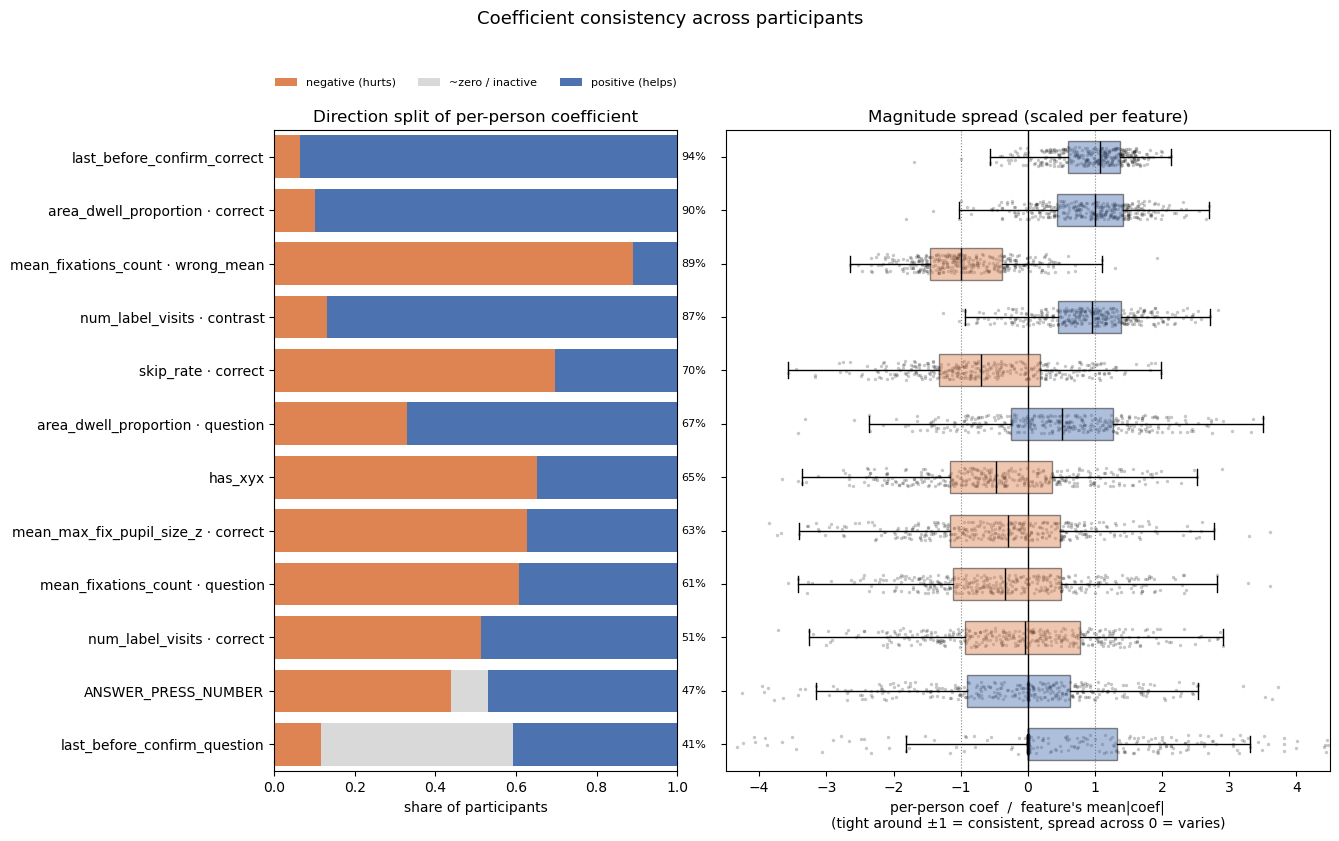

In [6]:
long_coef_df, consistency_df = CC.per_feature_coef_consistency(results_by_pid)
display(consistency_df[CC.CONSISTENCY_DISPLAY_COLS].round(3))
fig, _ = CC.plot_coef_consistency(long_coef_df, consistency_df, save=False)

### One feature, person by person

Every participant's coefficient for one feature, sorted, each with that person's own 95% interval from the fit on all their trials, so the whisker widths differ from person to person. The dashed and dash-dot lines are the mean and the median. Shown for the feature with the largest average coefficient; set `feature` to any of the 12 to see another.

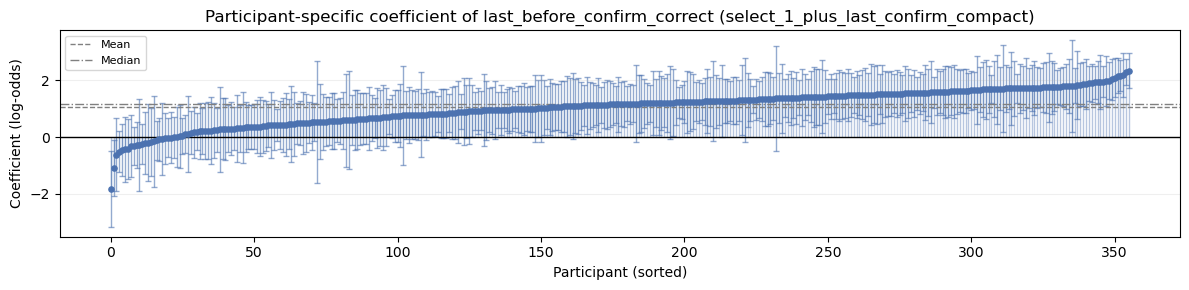

In [7]:
feature = mean_coef_df["feature"].iloc[0]   # largest mean coefficient by size
fig, coef_one_df, _ = CC.plot_participant_coef_effect(
    results_by_pid, feature, feature_set_tag=FEATURE_SET_TAG,
    dpi=100,   # the default 300 is meant for saved files
    save=False,
)

## 4. The same question for every feature, without a model
*`univariate_consistency.py`*

Coefficients exist only for the 12 model features. To ask of *every* feature in the table whether it relates to answering correctly the same way for everyone, this uses a measure that needs no model: for each participant, the Spearman correlation of the feature with answering correctly, over that person's own trials. Only participants with at least 20 trials and at least 5 correct and 5 wrong answers are scored, and a feature that never varies within a person is skipped for them (`coverage` is the share of scored participants it could be computed for).

This is a feature on its own, not holding the others fixed as a coefficient does, so it adds to section 3 rather than replacing it. With 54 trials per person the correlations are noisy: read a `dominant_share` near 0.5 as "no reliable direction", not as proof that people differ.

The figure shows the 25 features with the strongest average association: on the left the sign split (the label gives the share of the more common sign, and the coverage in brackets), on the right the spread of the per-person correlations. The table lists, among the 60 strongest, the ten whose direction agrees least across people.

participants: kept 288, dropped 72 (need >= 20 trials and >= 5 of each class)


,feature,n_valid,coverage,mean_r,dominant_share,std_r,mean_abs_r
52,mean_min_fix_pupil_size_z__question,288,1.000,0.004,0.510,0.180,0.144
53,first_encounter_avg_pupil_size_z__question,288,1.000,-0.011,0.514,0.180,0.143
54,mean_avg_fix_pupil_size_z__question,288,1.000,-0.009,0.517,0.179,0.143
51,mean_max_fix_pupil_size_z__question,288,1.000,-0.023,0.566,0.182,0.147
56,has_xyxy,274,0.951,-0.064,0.573,0.165,0.141
42,TimeSinceOffset_normalized_correct,288,1.000,0.051,0.660,0.193,0.159
50,ANSWER_PRESS_NUMBER,263,0.913,-0.087,0.669,0.167,0.148
30,num_label_visits__correct,288,1.000,0.076,0.670,0.186,0.163
41,mean_fixations_count__correct,288,1.000,0.076,0.688,0.182,0.160
58,mean_max_fix_pupil_size_z__contrast,288,1.000,0.075,0.698,0.152,0.137


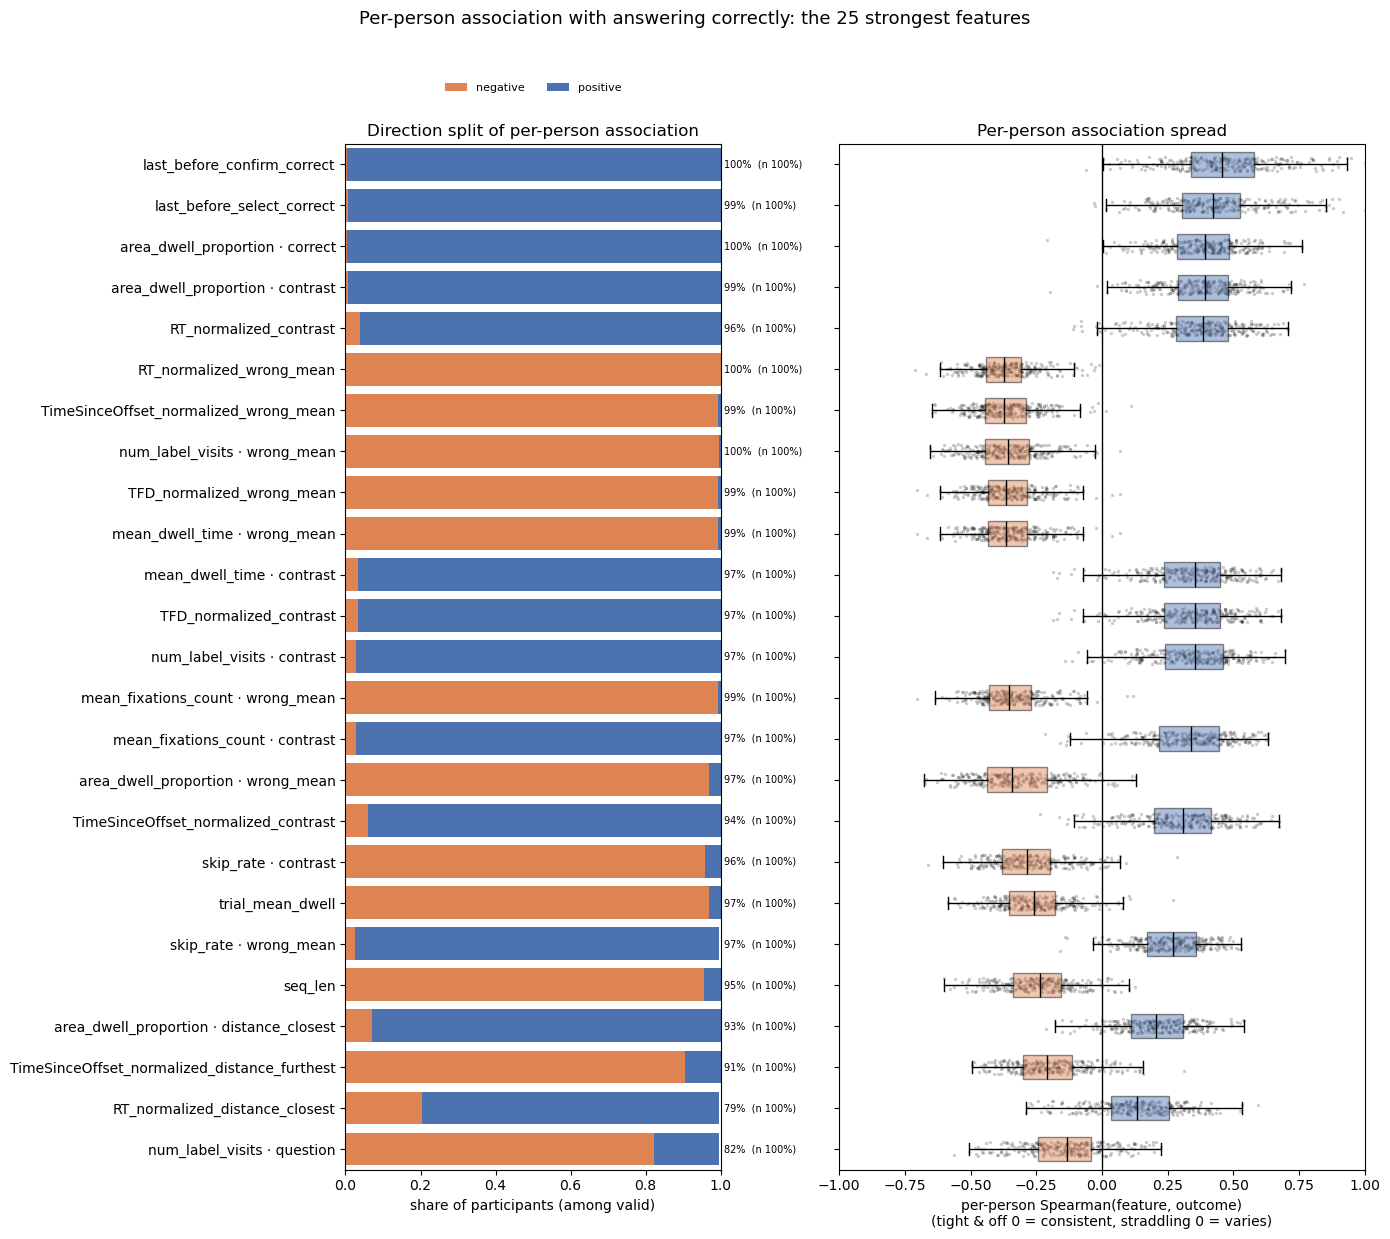

In [8]:
rmat_uni, uni_df = UC.per_person_univariate_consistency(trial_df, ALL_FEATURE_COLS, verbose=True)
display(UC.most_person_dependent(uni_df, n_strongest=60)[UC.UNIVARIATE_DISPLAY_COLS].head(10).round(3))
fig, _ = UC.plot_univariate_consistency(
    rmat_uni, uni_df, top_k=25,
    title="Per-person association with answering correctly: the 25 strongest features",
    save=False,
)

## 5. What sets apart the people the model predicts well
*`accuracy_characterization.py`*

Each participant's average of each feature is set against their balanced accuracy from section 2, and the lowest-scoring third of participants is compared with the highest-scoring third. People with fewer than 8 wrong answers are left out: with so few, balanced accuracy can hardly be estimated. Three figures:

1. balanced accuracy against the share of answers that were correct, and against the share of the rarer outcome;
2. the Spearman correlation of each feature's per-person average with balanced accuracy. **Positive** (blue) means people with more of this are predicted *better*;
3. the lowest third minus the highest third, in standard deviations of each feature across people. Here the sign means something else: **positive** means higher in the people the model does *worst* on.

It is run twice: on the 12 model features, then on every feature. A difference that shows up only in the second points to something the model never sees, a possible confound, rather than to a weakness in its own inputs.

[model features] 197/356 participants kept (n_wrong_trials >= 8); characterizing 'balanced_accuracy' over 12 features
[model features] low: 66 (balanced_accuracy <= 0.746)  |  high: 67 (balanced_accuracy >= 0.832)
    base_rate_correct : low=0.794  high=0.781
    minority_rate     : low=0.206  high=0.219
    n_trials          : low=53.985  high=53.985


,feature,spearman_r,abs_r
0,has_xyx,0.379,0.379
1,last_before_confirm_correct,0.367,0.367
2,area_dwell_proportion__correct,0.306,0.306
3,mean_max_fix_pupil_size_z__correct,0.216,0.216
4,num_label_visits__contrast,0.209,0.209
5,last_before_confirm_question,-0.206,0.206
6,area_dwell_proportion__question,-0.196,0.196
7,num_label_visits__correct,0.156,0.156
8,mean_fixations_count__question,-0.136,0.136
9,skip_rate__correct,-0.125,0.125


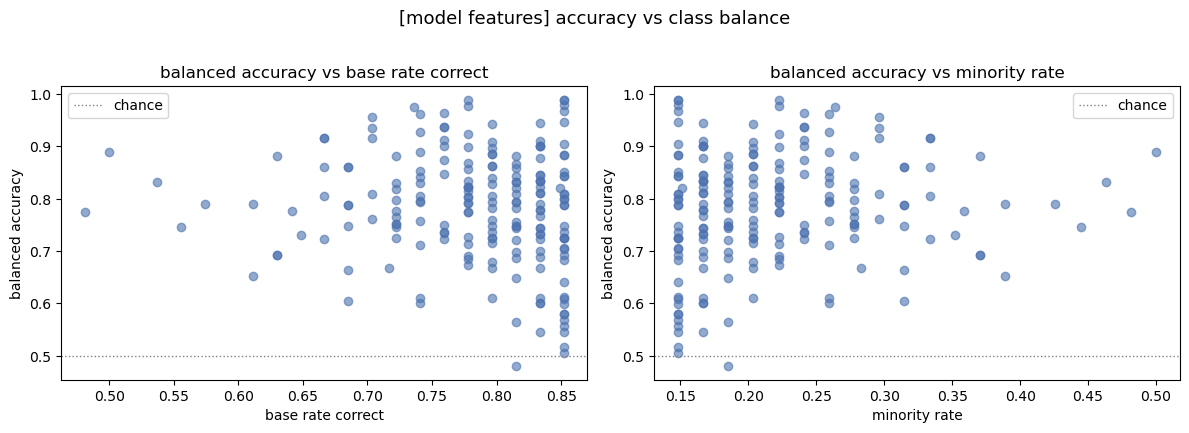

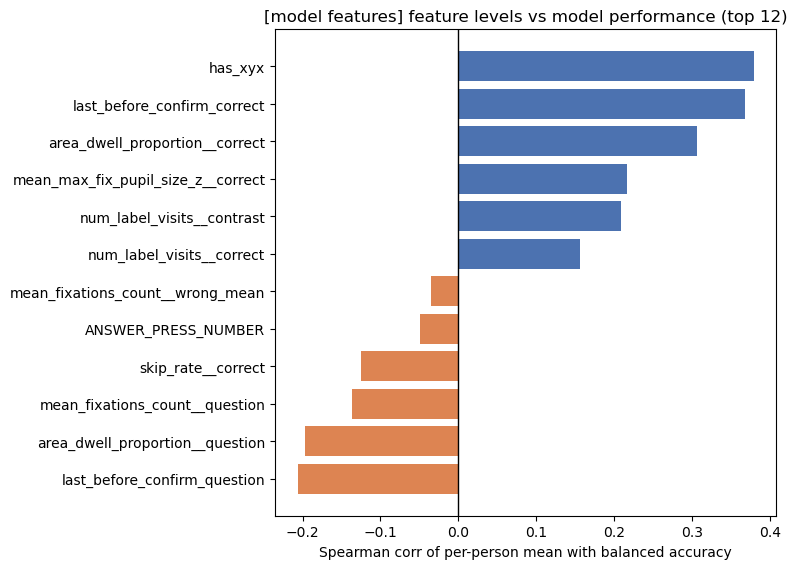

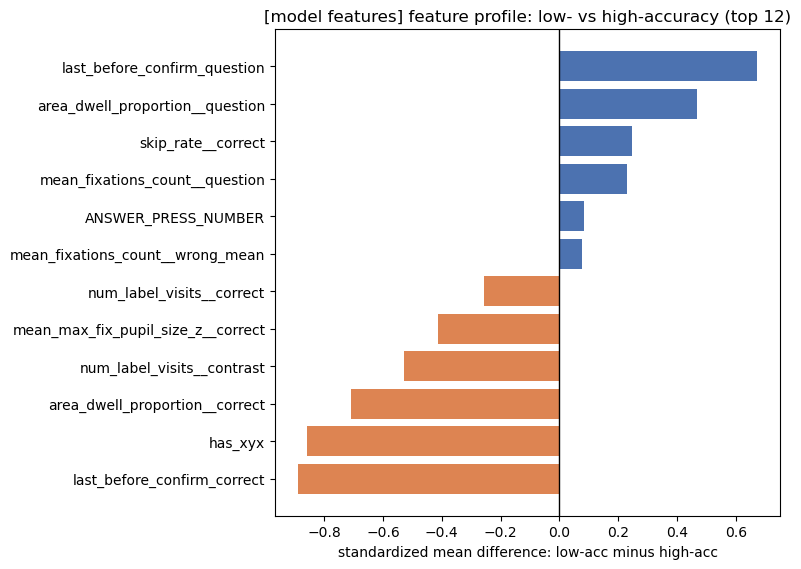

In [9]:
by_model_features = AC.characterize_accuracy(
    summary_df, trial_df, FEATURE_COLS, label="model features", verbose=True, save=False,
)
display(by_model_features["feat_corr"].round(3))

### Every feature

The class-balance figure is the same as above (it does not depend on the features), so it is not shown again.

[all features] 197/356 participants kept (n_wrong_trials >= 8); characterizing 'balanced_accuracy' over 98 features
[all features] low: 66 (balanced_accuracy <= 0.746)  |  high: 67 (balanced_accuracy >= 0.832)
    base_rate_correct : low=0.794  high=0.781
    minority_rate     : low=0.206  high=0.219
    n_trials          : low=53.985  high=53.985


,feature,spearman_r,abs_r
0,has_xyx,0.379,0.379
1,num_label_visits__distance_closest,0.375,0.375
2,last_before_confirm_correct,0.367,0.367
3,area_dwell_proportion__distance_closest,0.328,0.328
4,area_dwell_proportion__correct,0.306,0.306
5,area_dwell_proportion__contrast,0.291,0.291
6,has_xyxy,0.286,0.286
7,RT_normalized_distance_closest,0.253,0.253
8,last_before_select_correct,0.252,0.252
9,mean_dwell_time__distance_closest,0.230,0.230


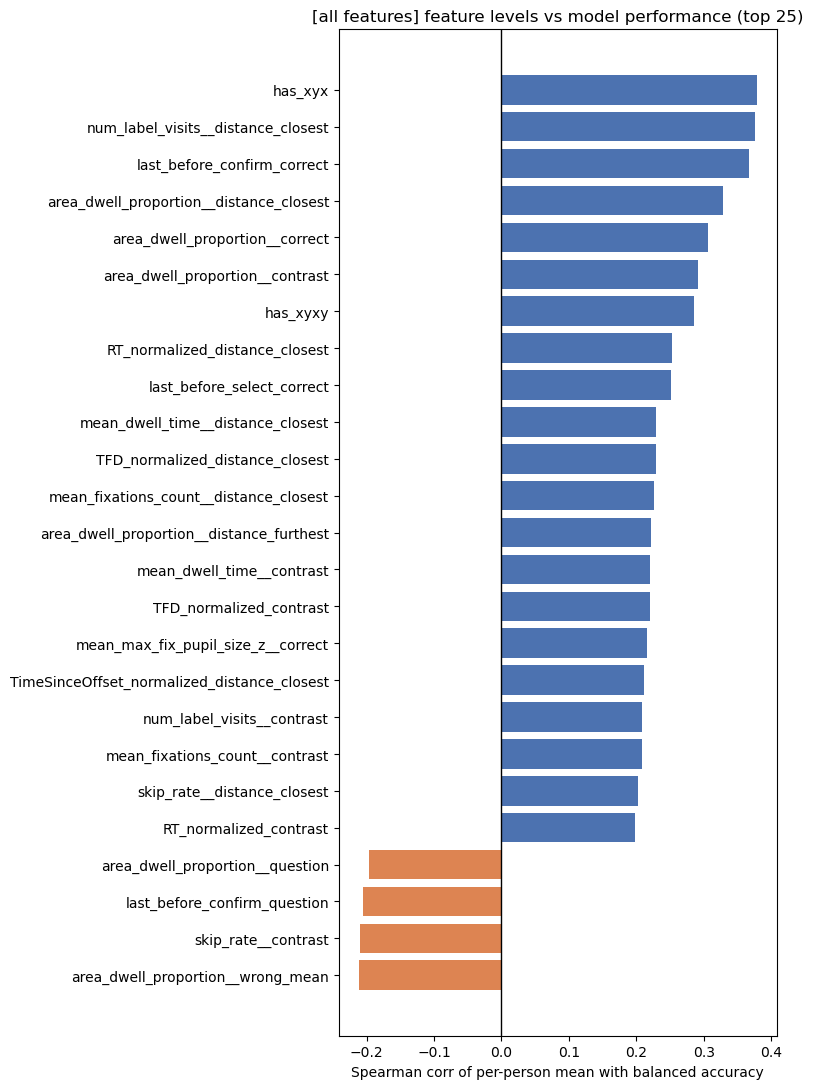

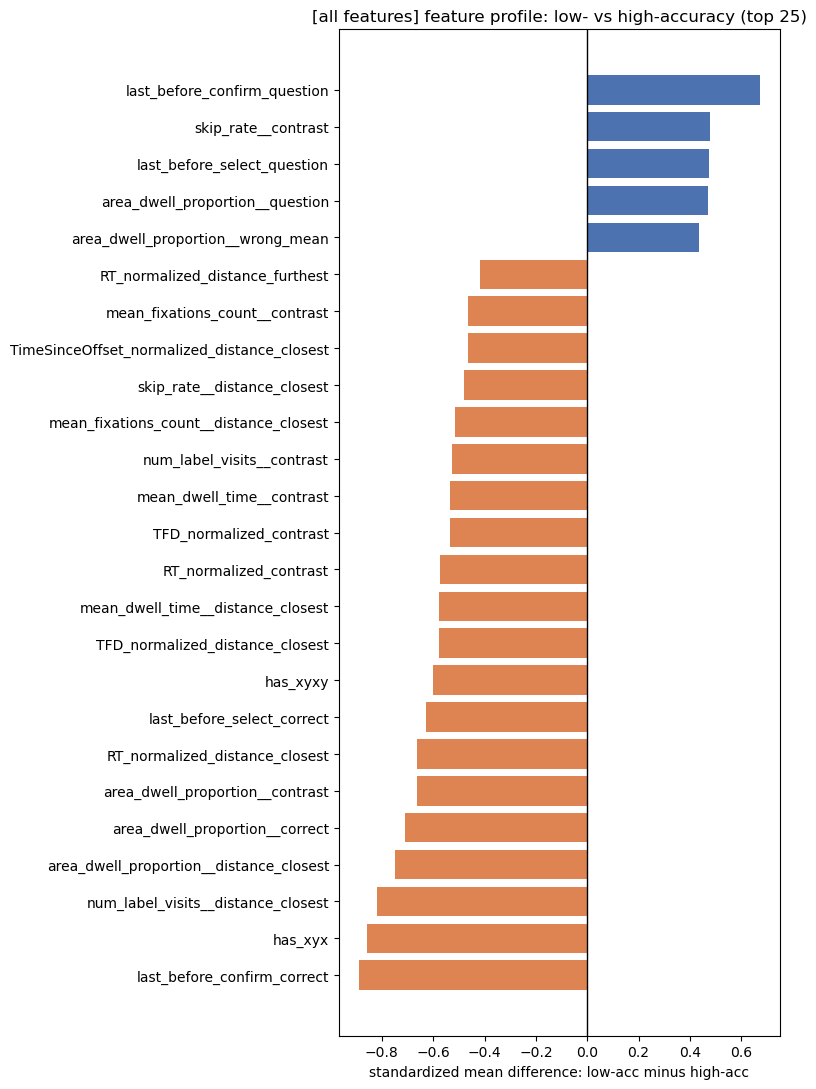

In [10]:
by_all_features = AC.characterize_accuracy(
    summary_df, trial_df, ALL_FEATURE_COLS, label="all features", verbose=True, save=False,
)
plt.close(by_all_features["figs"]["class_balance"])   # identical to the one above
display(by_all_features["feat_corr"].head(15).round(3))

## 6. Which kinds of mistakes the model makes
*`mistake_types.py`*

Every scored trial falls in one cell of the confusion matrix (`is_correct = 1` means the participant answered correctly):

| | model says correct | model says wrong |
|---|---|---|
| **participant correct** | TP: correct on right | FN: miss |
| **participant wrong** | FP: false alarm | TN: correct on wrong |

First, the counts pooled over every participant's scored trials.

19215 pooled held-out trials from 356 participants

Confusion quadrants (pooled over all trials):
  TP - correct on right   13846  ( 72.1%)
  TN - correct on wrong    2142  ( 11.1%)
  FP - false alarm          950  (  4.9%)
  FN - miss                2277  ( 11.9%)

Errors: 3227 total  |  FP false alarms 29.4%  |  FN misses 70.6%


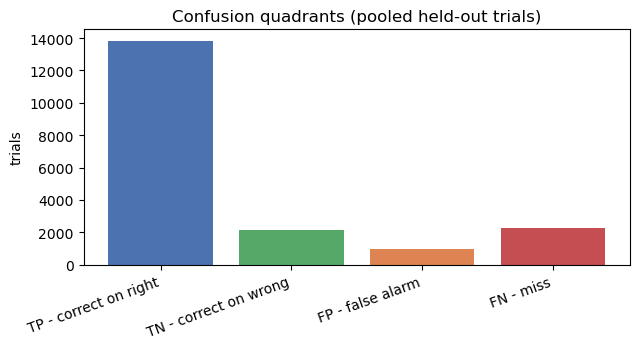

In [11]:
trials = MT.build_trial_prediction_table(results_by_pid)
quad_counts = MT.summarize_confusion_quadrants(trials, verbose=True)
fig, _ = MT.plot_confusion_quadrants(quad_counts, save=False)

### Per trial: what a mistake looks like next to a hit

Each feature is standardised over all pooled trials, so a quadrant's average reads as its distance from the typical trial, in standard deviations. Each comparison holds the participant's answer fixed and varies only whether the model got it right:

- `FN - TP | human correct`: among correctly answered trials, how a trial the model **missed** differs from one it **caught**. Positive means higher on the misses.
- `FP - TN | human wrong`: among wrongly answered trials, how a **false alarm** differs from a wrong answer the model flagged. Positive means higher on the false alarms.

quadrant,TP,TN,FP,FN,FN - TP | human correct (+) = elevated on misses,FP - TN | human wrong (+) = elevated on false alarms
area_dwell_proportion__correct,0.254,-0.938,-0.429,-0.483,-0.737,0.509
area_dwell_proportion__question,-0.055,0.162,0.130,0.128,0.183,-0.032
skip_rate__correct,-0.062,0.276,0.038,0.099,0.160,-0.238
has_xyx,-0.033,0.199,0.064,-0.014,0.019,-0.135
ANSWER_PRESS_NUMBER,-0.062,0.217,0.141,0.112,0.174,-0.075
num_label_visits__correct,0.007,-0.190,0.218,0.045,0.038,0.408
num_label_visits__contrast,0.217,-0.993,-0.152,-0.319,-0.535,0.841
mean_fixations_count__question,-0.111,0.423,0.249,0.171,0.282,-0.174
mean_fixations_count__wrong_mean,-0.221,0.860,0.369,0.378,0.599,-0.491
mean_max_fix_pupil_size_z__correct,-0.019,0.060,0.096,0.020,0.039,0.036


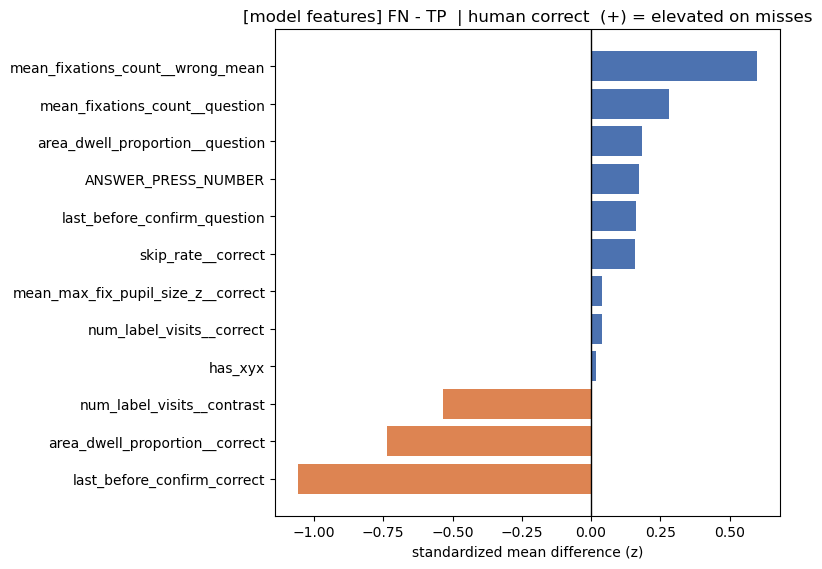

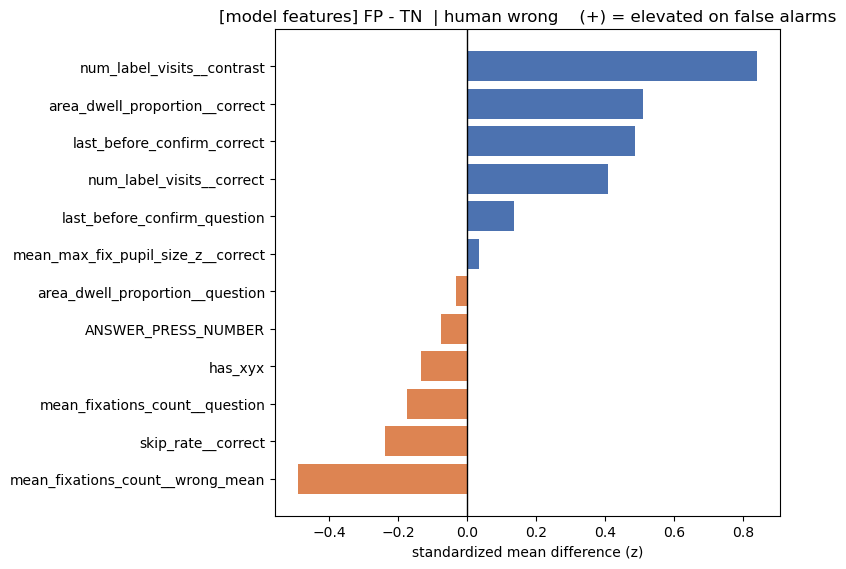

In [12]:
by_quadrant = MT.trial_feature_profile_by_quadrant(
    trials, FEATURE_COLS, label="model features", save=False,
)
display(by_quadrant["mean_z"].round(3))

### Per person: the two halves of balanced accuracy

Balanced accuracy is the average of sensitivity (how often the model is right on a person's correct answers) and specificity (how often it is right on their wrong answers). Each feature's per-person average is correlated with each half separately. Each half needs at least 8 trials of its kind, so specificity rests on fewer participants. A feature whose two bars point the same way goes with better predictions overall; one whose bars split goes with the model's skill on one kind of answer only. `r_balacc` in the table is the correlation with balanced accuracy itself, for reference.

[model features] sensitivity : 356 participants (n_correct_trials >= 8)
[model features] specificity : 197 participants (n_wrong_trials >= 8)


,feature,r_sensitivity,r_specificity,r_balacc,max_abs
0,last_before_confirm_correct,0.491,0.257,0.367,0.491
1,area_dwell_proportion__correct,0.355,0.215,0.306,0.355
2,has_xyx,0.231,0.346,0.379,0.346
3,num_label_visits__contrast,0.319,0.115,0.209,0.319
4,mean_fixations_count__question,-0.234,-0.083,-0.136,0.234
5,mean_max_fix_pupil_size_z__correct,0.108,0.217,0.216,0.217
6,area_dwell_proportion__question,-0.216,-0.158,-0.196,0.216
7,last_before_confirm_question,-0.160,-0.179,-0.206,0.179
8,mean_fixations_count__wrong_mean,-0.154,0.035,-0.035,0.154
9,skip_rate__correct,-0.073,-0.150,-0.125,0.150


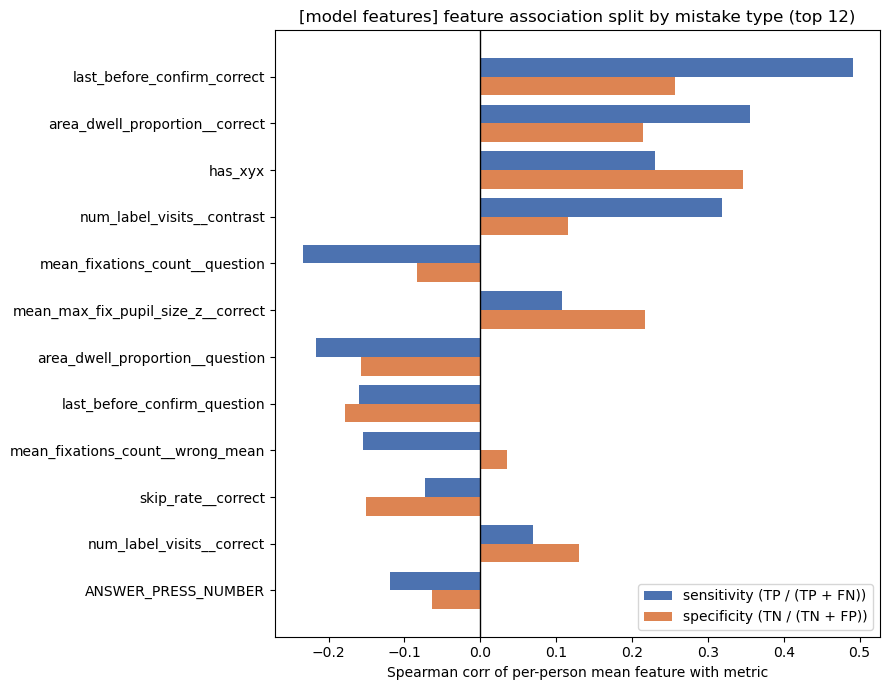

In [13]:
conf_df = MT.per_person_confusion(results_by_pid)
by_error_type = MT.characterize_accuracy_by_error_type(
    conf_df, trial_df, FEATURE_COLS, label="model features", verbose=True, save=False,
)
display(by_error_type["corr"].round(3))